<a href="https://colab.research.google.com/github/widyy123/hci-datavis-usability-prediction/blob/main/Untitled14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== SAMPEL DATASET EVALUASI INTERAKSI MANUSIA & KOMPUTER ===
   Task_Time_sec  Click_Count  Error_Rate_Pct  Chart_Clutter_Score  SUS_Score  \
0      16.490142     2.861736        2.647689             2.761515  83.829233   
1      14.297589     4.579213        2.767435             1.765263  87.712800   
2      13.609747     2.534270        2.241962             1.043360  76.375411   
3      13.313137     1.987169        2.314247             1.545988  77.938481   
4      19.396946     2.774224        2.067528             1.287626  82.278086   

           Usability_Status  
0  High Usability (Optimal)  
1  High Usability (Optimal)  
2  High Usability (Optimal)  
3  High Usability (Optimal)  
4  High Usability (Optimal)  

Akurasi Model Evaluasi HCI: 100.00%

=== CLASSIFICATION REPORT ===
                                   precision    recall  f1-score   support

         High Usability (Optimal)       1.00      1.00      1.00        40
Moderate Usability (Re-visualize)       1.00      1.0

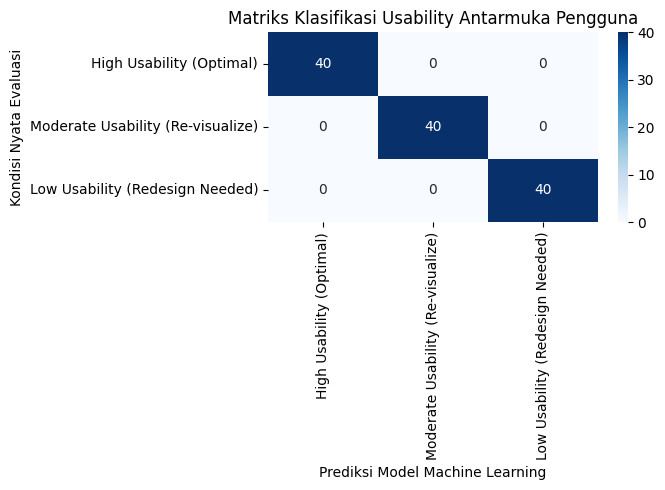

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. SIMULASI DATASET EVALUASI INTERAKSI PENGGUNA (HCI)

np.random.seed(42)
n_samples = 200

# Variabel Fitur HCI & Visualisasi Data:
# [Task_Time_sec, Click_Count, Error_Rate_Pct, Chart_Clutter_Score, SUS_Score]

# Kelas 0: Antarmuka Optimal (High Usability)
high_usa = np.random.normal(loc=[15.0, 3.0, 2.0, 2.0, 85.0], scale=[3.0, 1.0, 1.0, 0.5, 5.0], size=(n_samples, 5))

# Kelas 1: Perlu Perbaikan Visual (Moderate Usability)
mod_usa = np.random.normal(loc=[45.0, 8.0, 8.0, 6.0, 68.0], scale=[5.0, 1.5, 2.0, 1.0, 6.0], size=(n_samples, 5))

# Kelas 2: Antarmuka Buruk (Low Usability)
low_usa = np.random.normal(loc=[110.0, 18.0, 25.0, 9.0, 42.0], scale=[12.0, 3.0, 4.0, 0.8, 8.0], size=(n_samples, 5))

X = np.vstack((high_usa, mod_usa, low_usa))
y = np.array([0]*n_samples + [1]*n_samples + [2]*n_samples)

class_names = ['High Usability (Optimal)', 'Moderate Usability (Re-visualize)', 'Low Usability (Redesign Needed)']
feature_names = ['Task_Time_sec', 'Click_Count', 'Error_Rate_Pct', 'Chart_Clutter_Score', 'SUS_Score']

df = pd.DataFrame(X, columns=feature_names)
df['Usability_Status'] = [class_names[i] for i in y]

print("=== SAMPEL DATASET EVALUASI INTERAKSI MANUSIA & KOMPUTER ===")
print(df.head())

# 2. PREPROCESSING & SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. TRAINING MODEL CLASSIFICATION

mlp = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=300, random_state=42)
mlp.fit(X_train_scaled, y_train)

# 4. EVALUASI MODEL & REPORT

y_pred = mlp.predict(X_test_scaled)

print(f"\nAkurasi Model Evaluasi HCI: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=class_names))

# 5. VISUALISASI CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matriks Klasifikasi Usability Antarmuka Pengguna')
plt.xlabel('Prediksi Model Machine Learning')
plt.ylabel('Kondisi Nyata Evaluasi')
plt.tight_layout()
plt.show()